# Customer Support Ticket Classification


### Project overview
The project aims to classify customer support tickets into predefined support queues using the text of each ticket. In this part, we load the public dataset, inspect its structure, validate important columns, and prepare an English-only copy for the next project stages. Text cleaning and model development are handled by other team members.

## Part 1 — Introduction, Data Loading & Validation
 

## 1. Dataset source and usage

- **Dataset:** Multilingual Customer Support Tickets (`aa_dataset-tickets-multi-lang-5-2-50-version.csv`)
- **Source:** https://www.kaggle.com/datasets/tobiasbueck/multilingual-customer-support-tickets/data
- **License shown on Kaggle:** [CC BY 4.0 ]
- **License URL:** https://creativecommons.org/licenses/by/4.0/


**Dataset limitations to investigate:** the dataset contains more than one language, its target classes may be imbalanced, and missing values or repeated/near-duplicate ticket text may affect later modelling.

## 2. Import libraries

We use Pandas for tabular data inspection, NumPy for basic numerical operations, and `os` for paths and folders.

In [1]:
import os
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

## 3. Load the dataset



In [2]:
data_path = "../Data/raw/aa_dataset-tickets-multi-lang-5-2-50-version.csv"

if not os.path.exists(data_path):
    raise FileNotFoundError(
        f"Dataset not found at: {data_path}. Check the file location and path."
    )

df = pd.read_csv(data_path)
print("Dataset loaded successfully.")

Dataset loaded successfully.


## 4. Initial exploration

### 4.1 Preview the first rows

`head()` helps us check whether the file was read correctly and understand the values stored in each column.

In [3]:
df.head()

,subject,body,answer,type,queue,priority,language,version,tag_1,tag_2,tag_3,tag_4,tag_5,tag_6,tag_7,tag_8
0,Wesentlicher Sicherheitsvorfall,"Sehr geehrtes Support-Team,\n\nich möchte einen gravierenden Sicherheitsvorfall melden, der gege...",Vielen Dank für die Meldung des kritischen Sicherheitsvorfalls und die Bereitstellung der Übersi...,Incident,Technical Support,high,de,51,Security,Outage,Disruption,Data Breach,NaN,NaN,NaN,NaN
1,Account Disruption,"Dear Customer Support Team,\n\nI am writing to report a significant problem with the centralized...","Thank you for reaching out, <name>. We are aware of the outage affecting the centralized account...",Incident,Technical Support,high,en,51,Account,Disruption,Outage,IT,Tech Support,NaN,NaN,NaN
2,Query About Smart Home System Integration Features,"Dear Customer Support Team,\n\nI hope this message reaches you well. I am reaching out to reques...","Thank you for your inquiry. Our products support integration with Amazon Alexa, Google Assistant...",Request,Returns and Exchanges,medium,en,51,Product,Feature,Tech Support,NaN,NaN,NaN,NaN,NaN
3,Inquiry Regarding Invoice Details,"Dear Customer Support Team,\n\nI hope this message finds you well. I am reaching out to request ...",We appreciate you reaching out with your billing questions. The billing period generally begins ...,Request,Billing and Payments,low,en,51,Billing,Payment,Account,Documentation,Feedback,NaN,NaN,NaN
4,Question About Marketing Agency Software Compatibility,"Dear Support Team,\n\nI hope this message reaches you well. I am reaching out to ask about the c...","Thank you for your inquiry. Our product supports integration with major CRM, email marketing, an...",Problem,Sales and Pre-Sales,medium,en,51,Product,Feature,Feedback,Tech Support,NaN,NaN,NaN,NaN


### 4.2 Number of rows and columns



In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset shape:", df.shape)

Number of rows: 28587
Number of columns: 16
Dataset shape: (28587, 16)


### 4.3 Column names and data types

Use `info()` to inspect column names, non-null counts, and data types. A column with fewer non-null values than the total row count contains missing values.

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28587 entries, 0 to 28586
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   subject   24749 non-null  object
 1   body      28587 non-null  object
 2   answer    28580 non-null  object
 3   type      28587 non-null  object
 4   queue     28587 non-null  object
 5   priority  28587 non-null  object
 6   language  28587 non-null  object
 7   version   28587 non-null  int64 
 8   tag_1     28587 non-null  object
 9   tag_2     28574 non-null  object
 10  tag_3     28451 non-null  object
 11  tag_4     25529 non-null  object
 12  tag_5     14545 non-null  object
 13  tag_6     5874 non-null   object
 14  tag_7     2040 non-null   object
 15  tag_8     565 non-null    object
dtypes: int64(1), object(15)
memory usage: 3.5+ MB


### 4.4 Statistical summary

`describe(include="all")` provides a summary for both numeric and non-numeric columns.

In [6]:
df.describe(include="all")

,subject,body,answer,type,queue,priority,language,version,tag_1,tag_2,tag_3,tag_4,tag_5,tag_6,tag_7,tag_8
count,24749,28587,28580,28587,28587,28587,28587,28587.000000,28587,28574,28451,25529,14545,5874,2040,565
unique,24749,28587,28580,4,10,3,2,NaN,116,256,392,554,602,575,427,224
top,Wesentlicher Sicherheitsvorfall,"Sehr geehrtes Support-Team,\n\nich möchte einen gravierenden Sicherheitsvorfall melden, der gege...",Vielen Dank für die Meldung des kritischen Sicherheitsvorfalls und die Bereitstellung der Übersi...,Incident,Technical Support,medium,en,NaN,Security,Performance,IT,Tech Support,Tech Support,Tech Support,Tech Support,Tech Support
freq,1,1,1,11466,8362,11515,16338,NaN,5880,5903,6121,6568,4617,1847,391,77
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,278.382027,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,165.962935,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,51.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,52.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,400.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,400.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 5. Data validation



### 5.1 Check required columns

For this classification task, we expect a ticket text field and a target label. We plan to use `subject` and `body` as text inputs and `queue` as the target.

In [7]:
required_columns = ["subject", "body", "queue", "language"]

missing_columns = [column for column in required_columns if column not in df.columns]

if missing_columns:
    raise ValueError(f"Required columns are missing: {missing_columns}")

print("All required columns are available.")

All required columns are available.


### 5.2 Missing values

Count missing values in every column. 

In [8]:
missing_values = df.isnull().sum().sort_values(ascending=False)
missing_values

tag_8       28022
tag_7       26547
tag_6       22713
tag_5       14042
subject      3838
tag_4        3058
tag_3         136
tag_2          13
answer          7
language        0
version         0
queue           0
type            0
body            0
priority        0
tag_1           0
dtype: int64

In [9]:
print("Total missing cells:", int(df.isnull().sum().sum()))
print("Rows with at least one missing value:", int(df.isnull().any(axis=1).sum()))

Total missing cells: 98376


Rows with at least one missing value: 28177


### 5.3 Exact duplicate rows

`duplicated()` identifies rows that are identical across all columns. This is different from repeated ticket messages, which may have the same text but differ in another column.

In [10]:
duplicate_count = int(df.duplicated().sum())
print("Exact duplicate rows:", duplicate_count)

Exact duplicate rows: 0


### 5.4 Inspect the language values

The dataset is multilingual. First inspect the language labels and their counts. We will select English records for the initial project workflow.

In [11]:
language_counts = df["language"].value_counts(dropna=False)
language_counts

language
en    16338
de    12249
Name: count, dtype: int64

### 5.5 Inspect target labels

The `queue` column is the proposed target because it represents the support team/queue assigned to a ticket. Check the number of distinct labels and the number of examples in each label.

In [12]:
print("Number of queue categories:", df["queue"].nunique(dropna=True))
df["queue"].value_counts(dropna=False)

Number of queue categories: 10


queue
Technical Support                  8362
Product Support                    5252
Customer Service                   4268
IT Support                         3433
Billing and Payments               2788
Returns and Exchanges              1437
Service Outages and Maintenance    1148
Sales and Pre-Sales                 918
Human Resources                     576
General Inquiry                     405
Name: count, dtype: int64

## 6. Create an English-only working copy

Use Boolean filtering to select rows whose language code is `en`. `.copy()` makes an independent working DataFrame, leaving the original `df` unchanged.

In [13]:
df_english = df.loc[df["language"] == "en"].copy()

print("Original dataset shape:", df.shape)
print("English dataset shape:", df_english.shape)
print("English records:", len(df_english))

Original dataset shape: (28587, 16)
English dataset shape: (16338, 16)
English records: 16338


### 6.1 Validate the filtered copy

Check that the filter worked and that the important target/text fields are available.

In [14]:
print("Languages in filtered data:")
print(df_english["language"].value_counts(dropna=False))

print("\nMissing values in key columns:")
print(df_english[["subject", "body", "queue"]].isnull().sum())

print("\nTarget distribution in English data:")
df_english["queue"].value_counts(dropna=False)

Languages in filtered data:
language
en    16338
Name: count, dtype: int64

Missing values in key columns:
subject    2607
body          0
queue         0
dtype: int64

Target distribution in English data:


queue
Technical Support                  4737
Product Support                    3073
Customer Service                   2410
IT Support                         1942
Billing and Payments               1595
Returns and Exchanges               820
Service Outages and Maintenance     664
Sales and Pre-Sales                 513
Human Resources                     348
General Inquiry                     236
Name: count, dtype: int64

## 7. Initial validation summary

This summary collects the checks performed above.

In [15]:
validation_summary = {
    "original_rows": int(df.shape[0]),
    "original_columns": int(df.shape[1]),
    "exact_duplicate_rows": int(df.duplicated().sum()),
    "total_missing_cells": int(df.isnull().sum().sum()),
    "english_rows": int(len(df_english)),
    "english_missing_subject": int(df_english["subject"].isnull().sum()),
    "english_missing_body": int(df_english["body"].isnull().sum()),
    "english_missing_queue": int(df_english["queue"].isnull().sum()),
    "english_queue_categories": int(df_english["queue"].nunique(dropna=True)),
}

pd.Series(validation_summary, name="Value")

original_rows               28587
original_columns               16
exact_duplicate_rows            0
total_missing_cells         98376
english_rows                16338
english_missing_subject      2607
english_missing_body            0
english_missing_queue           0
english_queue_categories       10
Name: Value, dtype: int64

## 8. Save the filtered dataset

Save the English-only copy for the next stage. Keep the original raw file unchanged. 

In [16]:
output_dir = "../data/processed"
os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(output_dir, "english_tickets.csv")
df_english.to_csv(output_path, index=False)

print("English dataset saved to:", output_path)

English dataset saved to: ../data/processed\english_tickets.csv


In [17]:

# Part 3 - Exploratory Data Analysis (EDA)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the English-only dataset
df_eda = pd.read_csv("../Data/processed/english_tickets.csv")

print("Dataset shape:", df_eda.shape)

# Count tickets in each support category
category_counts = df_eda["queue"].value_counts()

print("\nTicket Category Distribution:")
print(category_counts)


Dataset shape: (16338, 16)

Ticket Category Distribution:
queue
Technical Support                  4737
Product Support                    3073
Customer Service                   2410
IT Support                         1942
Billing and Payments               1595
Returns and Exchanges               820
Service Outages and Maintenance     664
Sales and Pre-Sales                 513
Human Resources                     348
General Inquiry                     236
Name: count, dtype: int64


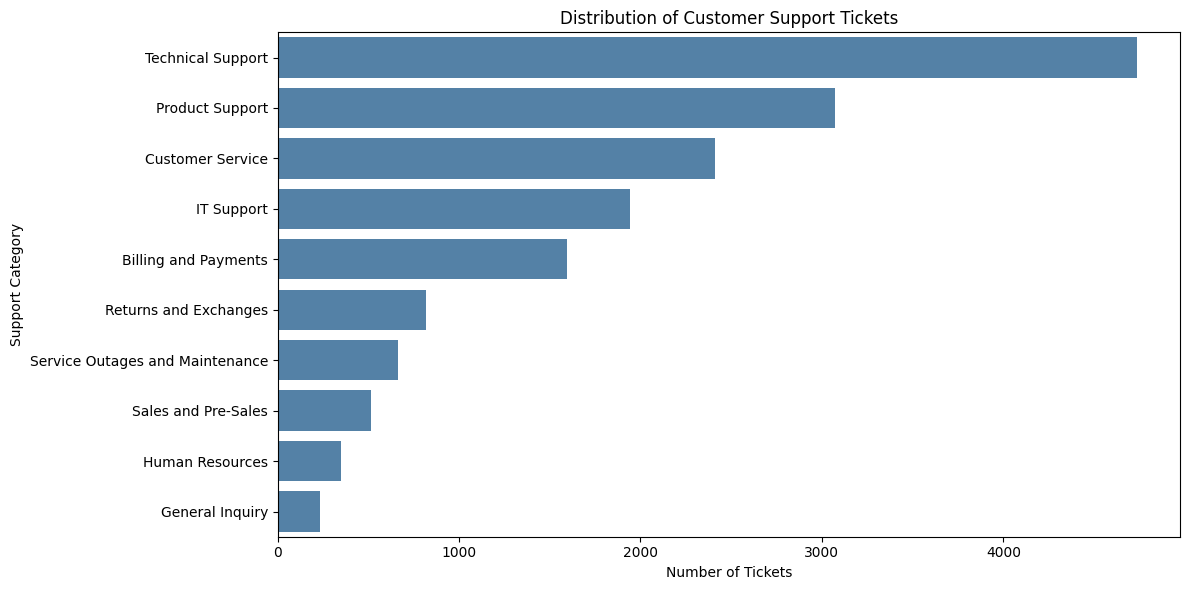

In [18]:

# Visualization 1: Ticket Category Distribution

plt.figure(figsize=(12, 6))

sns.barplot(
    x=category_counts.values,
    y=category_counts.index,
    color="steelblue"
)

plt.title("Distribution of Customer Support Tickets")
plt.xlabel("Number of Tickets")
plt.ylabel("Support Category")

plt.tight_layout()
plt.show()


Ticket Type Distribution:
type
Incident    6571
Request     4665
Problem     3397
Change      1705
Name: count, dtype: int64


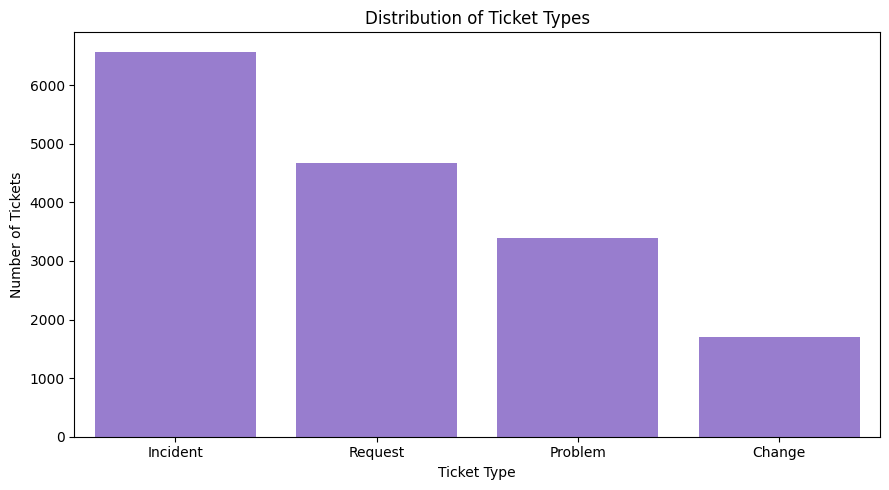

In [19]:

# Visualization 2: Ticket Type Distribution

type_counts = df_eda["type"].value_counts()

print("Ticket Type Distribution:")
print(type_counts)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=type_counts.index,
    y=type_counts.values,
    color="mediumpurple"
)

plt.title("Distribution of Ticket Types")
plt.xlabel("Ticket Type")
plt.ylabel("Number of Tickets")

plt.tight_layout()
plt.show()


Ticket Priority Distribution:
priority
medium    6618
high      6346
low       3374
Name: count, dtype: int64


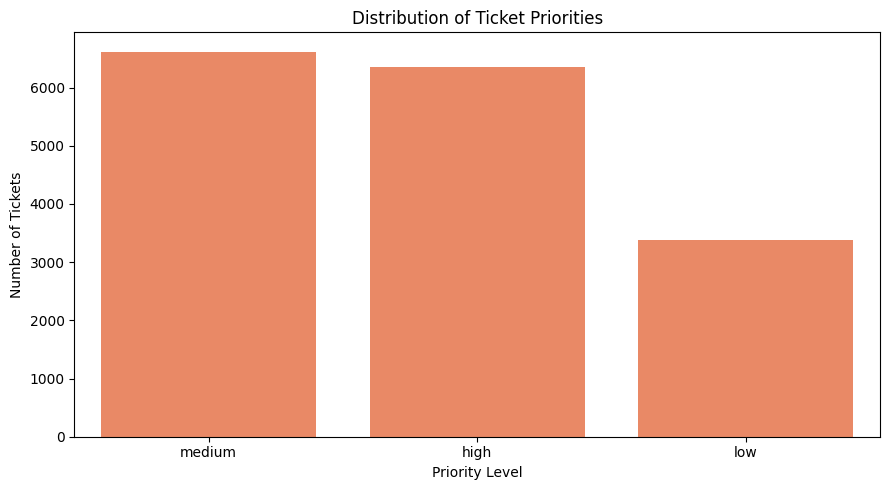

In [20]:

# Visualization 3: Ticket Priority Distribution

priority_counts = df_eda["priority"].value_counts()

print("Ticket Priority Distribution:")
print(priority_counts)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=priority_counts.index,
    y=priority_counts.values,
    color="coral"
)

plt.title("Distribution of Ticket Priorities")
plt.xlabel("Priority Level")
plt.ylabel("Number of Tickets")

plt.tight_layout()
plt.show()


Ticket Text Length Statistics:
count    16338.000000
mean        58.643041
std         26.868554
min          2.000000
25%         36.000000
50%         60.000000
75%         82.000000
max        172.000000
Name: word_count, dtype: float64


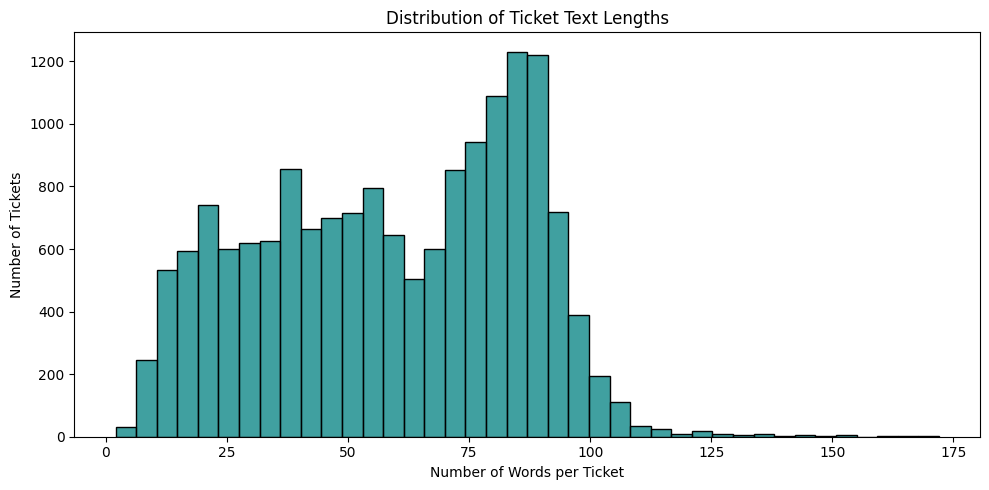

In [21]:

# Visualization 4: Ticket Text Length Distribution

# Combine subject and body without modifying the original columns
df_eda["ticket_text"] = (
    df_eda["subject"].fillna("") + " " +
    df_eda["body"].fillna("")
).str.strip()

# Calculate text length in words
df_eda["word_count"] = df_eda["ticket_text"].str.split().str.len()

print("Ticket Text Length Statistics:")
print(df_eda["word_count"].describe())

# Plot distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_eda,
    x="word_count",
    bins=40,
    color="teal"
)

plt.title("Distribution of Ticket Text Lengths")
plt.xlabel("Number of Words per Ticket")
plt.ylabel("Number of Tickets")

plt.tight_layout()
plt.show()


Average Word Count by Category:
queue
General Inquiry                    62.50
Billing and Payments               59.43
Technical Support                  59.03
Customer Service                   58.88
IT Support                         58.29
Product Support                    58.18
Service Outages and Maintenance    58.00
Sales and Pre-Sales                57.77
Returns and Exchanges              57.69
Human Resources                    56.27
Name: word_count, dtype: float64


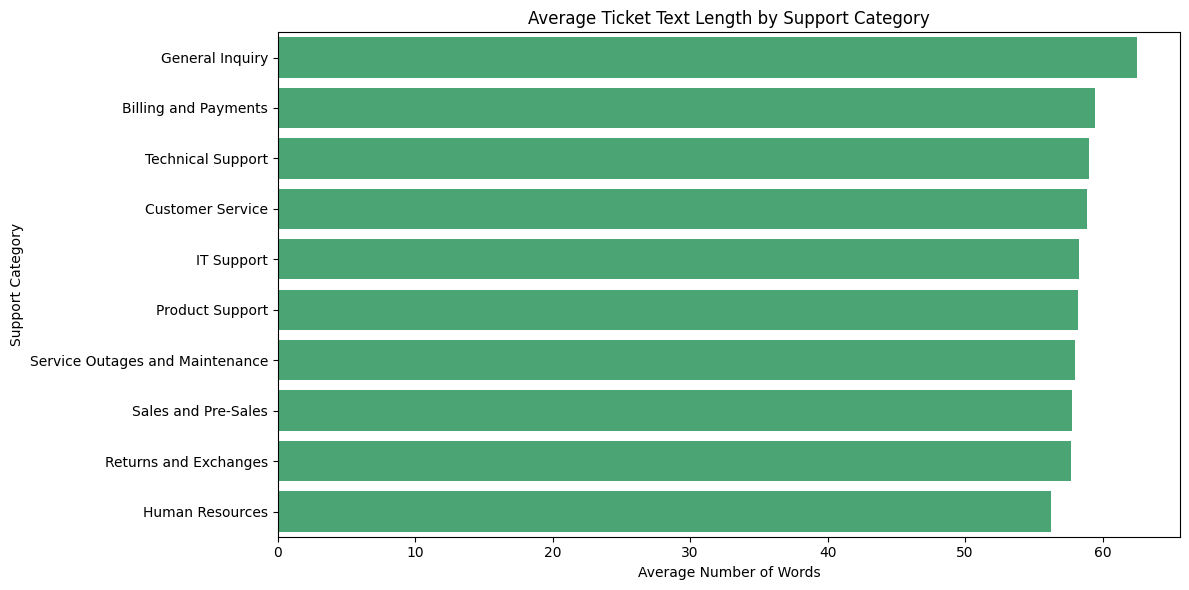

In [22]:

# Visualization 5: Average Text Length by Category

avg_length = (
    df_eda.groupby("queue")["word_count"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Word Count by Category:")
print(avg_length.round(2))

plt.figure(figsize=(12, 6))

sns.barplot(
    x=avg_length.values,
    y=avg_length.index,
    color="mediumseagreen"
)

plt.title("Average Ticket Text Length by Support Category")
plt.xlabel("Average Number of Words")
plt.ylabel("Support Category")

plt.tight_layout()
plt.show()


Top 15 Most Common Words:
[('data', 13928), ('support', 8562), ('issue', 7910), ('assistance', 6675), ('security', 6025), ('software', 5931), ('customer', 5854), ('information', 5454), ('provide', 5341), ('appreciate', 5224), ('analytics', 5064), ('problem', 5047), ('digital', 4722), ('medical', 4710), ('integration', 4691)]


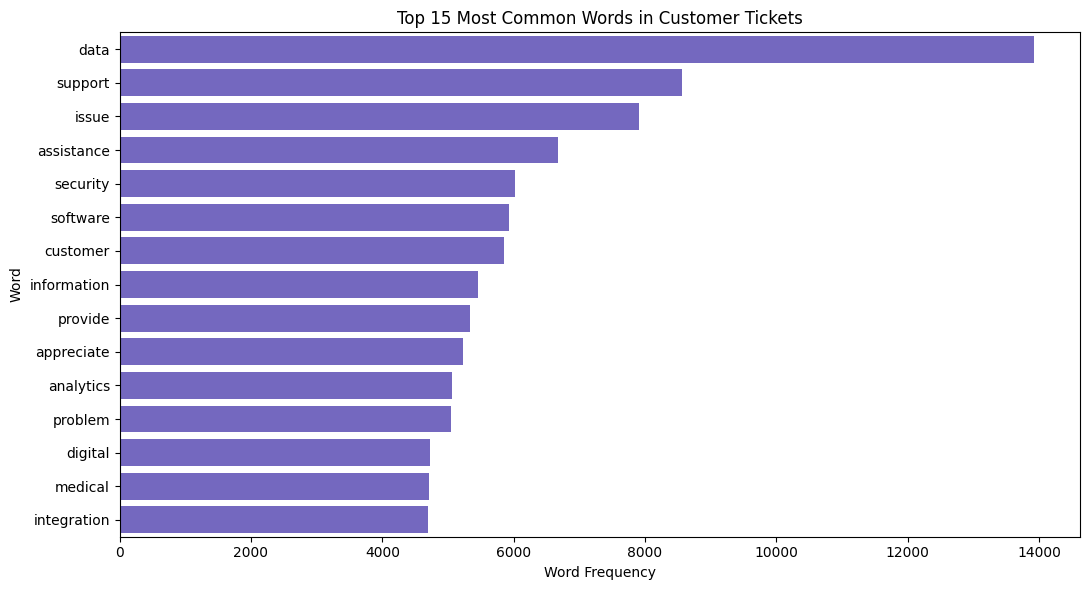

In [23]:

# Visualization 6: Most Common Words in Tickets

from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
import re

# Combine all ticket texts
all_text = " ".join(df_eda["ticket_text"].fillna("").astype(str))

# Extract English words
words = re.findall(r"\b[a-zA-Z]+\b", all_text.lower())

# Remove common English stop words
filtered_words = [
    word for word in words
    if word not in ENGLISH_STOP_WORDS and len(word) > 2
]

# Count the 15 most frequent words
word_counts = Counter(filtered_words).most_common(15)

words_labels = [word for word, count in word_counts]
words_values = [count for word, count in word_counts]

print("Top 15 Most Common Words:")
print(word_counts)

plt.figure(figsize=(11, 6))

sns.barplot(
    x=words_values,
    y=words_labels,
    color="slateblue"
)

plt.title("Top 15 Most Common Words in Customer Tickets")
plt.xlabel("Word Frequency")
plt.ylabel("Word")

plt.tight_layout()
plt.show()


Missing Values by Column:
tag_8      16057
tag_7      15204
tag_6      12968
tag_5       7922
subject     2607
tag_4       1711
tag_3         69
tag_2          6
answer         3
dtype: int64


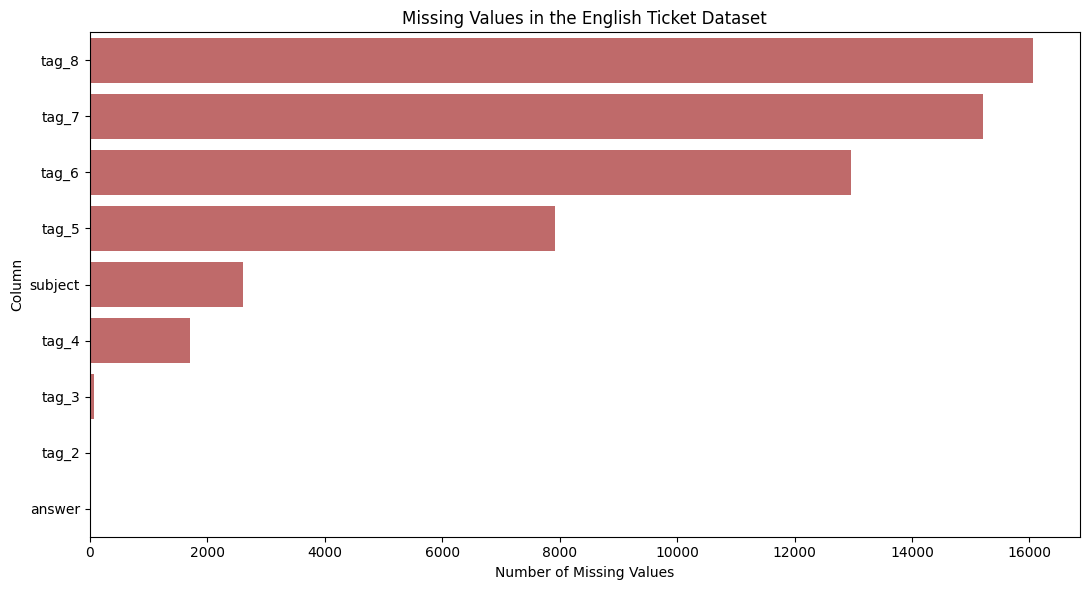

In [24]:

# Visualization 7: Missing Values Analysis

missing_counts = df_eda.isnull().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(
    ascending=False
)

print("Missing Values by Column:")
print(missing_counts)

plt.figure(figsize=(11, 6))

sns.barplot(
    x=missing_counts.values,
    y=missing_counts.index,
    color="indianred"
)

plt.title("Missing Values in the English Ticket Dataset")
plt.xlabel("Number of Missing Values")
plt.ylabel("Column")

plt.tight_layout()
plt.show()


## Part 3 — Exploratory Data Analysis (EDA) & Visualization

### EDA Summary and Key Findings

The exploratory data analysis was conducted on 16,338 English-language customer support tickets across 10 support categories.

**1. Category Distribution:** Technical Support has the highest number of tickets (4,737), while General Inquiry has the lowest (236). This indicates a noticeable class imbalance in the target variable.

**2. Ticket Types:** Incident tickets are the most frequent, followed by Request, Problem, and Change tickets.

**3. Ticket Priorities:** Medium- and high-priority tickets account for most records, while low-priority tickets are less frequent.

**4. Text Length:** The average ticket contains approximately 58.64 words, with a median of 60 words. Ticket lengths range from 2 to 172 words.

**5. Average Length by Category:** The average text length is relatively similar across categories, ranging from approximately 56 to 62 words.

**6. Common Words:** The most frequent terms include "data", "support", "issue", "assistance", and "security". These terms provide an overview of recurring vocabulary in the dataset.

**7. Missing Values:** Missing values are concentrated in the optional tag columns. The subject column contains 2,607 missing values, representing approximately 16% of English tickets.

### Overall Findings

The analysis reveals an imbalanced distribution of support categories, relatively consistent ticket lengths, and recurring vocabulary across customer support messages. These findings provide useful context for the subsequent preprocessing and machine learning stages.